
<p align="center"> In the Name of God </p>

<table style="width: 100%; text-align: center;">
  <tr>
    <td style="width: 20%;"><img src="https://i.ibb.co/yXKQmtZ/logo1.png" alt="Left Logo" width="100"></td>
    <td style="width: 60%;">
      <p>Faculty of Electrical and Computer Engineering</p>
      <p>Interactive learning - Fall 2023-2024</p>
      <p>Assignment Series 4</p>
      <p>Markov Decision Processes and Dynamic programming</p>
    </td>
    <td style="width: 20%;"><img src="https://i.ibb.co/wLjqFkw/logo2.png" alt="Right Logo" width="100"></td>
  </tr>
  
</table>
<p align="center">Fatemeh Mohammadi - 810199489</p>
<hr>



In [1]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch
import gym
import math
import random
import numpy as np
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
from collections import namedtuple, deque
from itertools import count
from scipy.stats import sem
import gym.wrappers


In [3]:
# Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# <font color = lightGreen> PART 3:
 </font>

In [4]:
env = gym.make("CartPole-v1")
n_actions = env.action_space.n
state, info = env.reset()
n_observations = len(state)

In [5]:
# Hyperparameters
BATCH_SIZE = 128
GAMMA = 0.99
EPS_START = 0.9
EPS_END = 0.05
EPS_DECAY = 1000
TAU = 0.005
LR = 1e-4
LR = 1e-4
num_episodes = 500 if torch.cuda.is_available() else 50


## <font color = lightBlue> question 6:
 </font>

In [6]:
class ReplayMemory:
    def __init__(self, capacity):
        self.memory = deque([], maxlen=capacity)

    def push(self, *args):
        self.memory.append(Transition(*args))

    def sample(self, batch_size):
        return random.sample(self.memory, batch_size)

    def __len__(self):
        return len(self.memory)

In [7]:
class DQN(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(DQN, self).__init__()
        self.fc1 = nn.Linear(input_dim, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, output_dim)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

In [8]:
def select_action(state, policy_net, steps_done):
    eps_threshold = EPS_END + (EPS_START - EPS_END) * math.exp(-1.0 * steps_done / EPS_DECAY)
    if random.random() > eps_threshold:
        with torch.no_grad():
            return policy_net(state).argmax(dim=1).view(1, 1)
    else:
        return torch.tensor([[env.action_space.sample()]], device=device, dtype=torch.long)

In [9]:
def optimize_model(memory, policy_net, target_net, optimizer):
    if len(memory) < BATCH_SIZE:
        return

    transitions = memory.sample(BATCH_SIZE)
    batch = Transition(*zip(*transitions))

    non_final_mask = torch.tensor(tuple(map(lambda s: s is not None, batch.next_state)), device=device, dtype=torch.bool)
    non_final_next_states = torch.cat([s for s in batch.next_state if s is not None])
    state_batch = torch.cat(batch.state)
    action_batch = torch.cat(batch.action)
    reward_batch = torch.cat(batch.reward)

    state_action_values = policy_net(state_batch).gather(1, action_batch)

    next_state_values = torch.zeros(BATCH_SIZE, device=device)
    with torch.no_grad():
        next_state_values[non_final_mask] = target_net(non_final_next_states).max(1)[0]

    expected_state_action_values = reward_batch + GAMMA * next_state_values

    loss = F.smooth_l1_loss(state_action_values, expected_state_action_values.unsqueeze(1))

    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_value_(policy_net.parameters(), 100)
    optimizer.step()

In [10]:
env = gym.make("CartPole-v1")
state, _ = env.reset()
state_size = len(state)
action_size = env.action_space.n

policy_net = DQN(state_size, action_size).to(device)
target_net = DQN(state_size, action_size).to(device)
target_net.load_state_dict(policy_net.state_dict())
target_net.eval()
Transition = namedtuple('Transition', ['state', 'action', 'next_state', 'reward'])

memory = ReplayMemory(10000)
optimizer = optim.Adam(policy_net.parameters(), lr=LR)
steps_done = 0

episode_durations = []
reward_history = []
num_runs = 10



In [11]:
for run in range(num_runs):
    run_rewards = []
    for i_episode in range(num_episodes):
        state, _ = env.reset()
        state = torch.tensor([state], device=device, dtype=torch.float32)

        episode_reward = 0
        for t in count():
            action = select_action(state, policy_net, steps_done)
            steps_done += 1
            observation, reward, done, truncated, _ = env.step(action.item())
            reward = torch.tensor([reward], device=device)
            episode_reward += reward.item()

            next_state = None if done else torch.tensor([observation], device=device, dtype=torch.float32)

            memory.push(state, action, next_state, reward)
            state = next_state

            optimize_model(memory, policy_net, target_net, optimizer)

            # Update the target network
            with torch.no_grad():
                for param, target_param in zip(policy_net.parameters(), target_net.parameters()):
                    target_param.data.copy_(TAU * param.data + (1.0 - TAU) * target_param.data)

            if done or truncated:
                run_rewards.append(episode_reward)
                break

    reward_history.append(run_rewards)



C:\Users\AFRAA\AppData\Local\Temp\ipykernel_33808\3221535780.py:5: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\bld\libtorch_1736880243185\work\torch\csrc\utils\tensor_new.cpp:281.)
  state = torch.tensor([state], device=device, dtype=torch.float32)
c:\Users\AFRAA\.conda\envs\university_env\Lib\site-packages\gym\utils\passive_env_checker.py:233: DeprecationWarning: `np.bool8` is a deprecated alias for `np.bool_`.  (Deprecated NumPy 1.24)
  if not isinstance(terminated, (bool, np.bool8)):


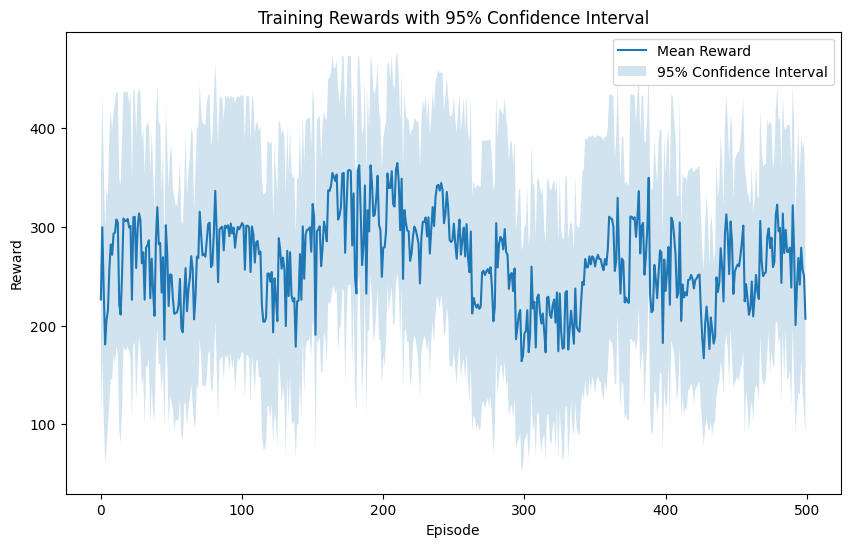

In [14]:
data = np.array(reward_history)
mean_rewards = np.mean(data, axis=0)
confidence_interval = sem(data, axis=0) * 1.96  # 95% confidence interval

plt.figure(figsize=(10, 6))
plt.plot(mean_rewards, label="Mean Reward")
plt.fill_between(range(len(mean_rewards)),
                 mean_rewards - confidence_interval,
                 mean_rewards + confidence_interval,
                 alpha=0.2, label="95% Confidence Interval")
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("Training Rewards with 95% Confidence Interval")
plt.legend()
plt.show()


c:\Users\AFRAA\.conda\envs\university_env\Lib\site-packages\gym\wrappers\record_video.py:75: UserWarning: WARN: Overwriting existing videos at c:\f102m-data\-University\Uni 09\1-RL\CAs-GIT\UT_RL\RL_HW4\video1 folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(
